# TE-292 — Aula 3: juntando dados de manutenção

## Etapa C — Da tabela integrada a uma probabilidade de falha

**Tempo previsto:** 45 minutos

Esta é uma demonstração de fechamento. O objetivo não é aprender todos os
detalhes do LightGBM, mas observar como uma tabela bem construída pode alimentar
um modelo preditivo — um algoritmo que aprende padrões nos dados para estimar um
resultado ainda desconhecido.

O LightGBM é um algoritmo baseado em várias árvores de decisão. Ele será estudado
com mais cuidado em aulas posteriores.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
)

sns.set_theme(style="darkgrid")
%matplotlib inline

DATA_DIR = Path("dados_manutencao")
OUTPUT_DIR = Path("output")
model_table_path = OUTPUT_DIR / "asset_modelization_table.csv"

if not model_table_path.exists():
    raise FileNotFoundError(
        "A tabela integrada não foi encontrada. Execute A e B antes de C."
    )

model_table = pd.read_csv(model_table_path)

print(f"Arquivo de entrada: {model_table_path}")
print(f"Quantidade de linhas e colunas: {model_table.shape}")
assert "Unnamed: 0" not in model_table.columns
assert model_table["Asset"].is_unique
model_table.head()

Arquivo de entrada: output/asset_modelization_table.csv
Quantidade de linhas e colunas: (1894, 19)


,Asset,Time_min,Use_min,nb_km,R044,R064,R119,R193,R364,R396,R417,R446,R565,R575,R606,R707,R782,R783,failure_bin
0,A000204,46,31449.650982,1763.11,NaN,NaN,0.857143,1.629630,1.000000,NaN,NaN,1.000,3.785714,NaN,NaN,2.229885,NaN,NaN,1.0
1,A000270,435,26378.556339,658.21,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN
2,A000463,30,30451.537250,1442.47,NaN,NaN,1.000000,2.086957,1.000000,NaN,NaN,1.000,NaN,NaN,NaN,3.318841,NaN,1.5,1.0
3,A000495,6,30851.249561,1689.00,NaN,NaN,0.800000,2.928571,1.444444,NaN,NaN,1.625,8.040816,NaN,NaN,2.164179,NaN,NaN,0.0
4,A001201,395,26136.394866,1051.51,NaN,NaN,NaN,1.166667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.900000,NaN,NaN,0.0


## 1. Informações de entrada e resposta esperada

As colunas usadas pelo modelo são chamadas de **atributos** ou **features**. Elas
foram construídas nas etapas anteriores:

- **uso:** `Time_min`, `Use_min`, `nb_km`;
- **consumo por motivo:** `R193`, `R364`, `R417`, `R446`, `R565`, `R707`,
  `R783`.

A coluna que queremos prever é chamada de **alvo** ou **target**. Nosso alvo é
`failure_bin`: `0` significa sem falha e `1` significa com falha.

O modelo aprende usando exemplos cuja resposta já é conhecida. Esse processo é
chamado de **aprendizado supervisionado**. Por isso, ativos sem valor em
`failure_bin` não podem participar do treinamento. Valores faltantes nos
atributos podem permanecer, pois o LightGBM sabe tratá-los internamente.

In [2]:
features = [
    "Time_min",
    "Use_min",
    "nb_km",
    "R193",
    "R364",
    "R417",
    "R446",
    "R565",
    "R707",
    "R783",
]
target = "failure_bin"

labeled = model_table.loc[model_table[target].notna()].copy()
X = labeled[features]
y = labeled[target].astype(int)

print(f"Ativos com rótulo: {len(labeled):,}")
print(f"Ativos sem rótulo: {model_table[target].isna().sum():,}")
print("\nDistribuição do alvo")
print(y.value_counts().rename(index={0: "sem falha", 1: "com falha"}).to_string())
print(f"Taxa de falha: {y.mean():.2%}")
print(f"Valores ausentes nos atributos: {X.isna().sum().sum():,}")

Ativos com rótulo: 1,805
Ativos sem rótulo: 89

Distribuição do alvo
failure_bin
sem falha    1357
com falha     448
Taxa de falha: 24.82%
Valores ausentes nos atributos: 4,699


## 2. Separando dados para aprender e para verificar

Dividiremos os exemplos em dois grupos:

- **treino:** dados usados pelo modelo para aprender;
- **teste:** dados reservados para verificar o desempenho após o aprendizado.

O teste fica isolado para representar exemplos que o modelo ainda não viu. No
código, `stratify=y` mantém aproximadamente a mesma proporção de falhas nos dois
grupos.

As configurações internas do algoritmo são chamadas de **hiperparâmetros**. Elas
serão mantidas fixas nesta demonstração. Aprenderemos a escolhê-las e validar o
modelo em aulas posteriores.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y,
)

classifier = lgb.LGBMClassifier(
    learning_rate=0.05,
    n_estimators=200,
    num_leaves=31,
    max_bin=125,
    importance_type="gain",
    random_state=42,
    verbose=-1,
)
classifier.fit(X_train, y_train)

y_probability = classifier.predict_proba(X_test)[:, 1]
y_pred = (y_probability >= 0.50).astype(int)

print(f"Treino: {len(X_train):,} ativos; falhas = {y_train.mean():.2%}")
print(f"Teste:  {len(X_test):,} ativos; falhas = {y_test.mean():.2%}")

Treino: 1,263 ativos; falhas = 24.78%
Teste:  542 ativos; falhas = 24.91%


## 3. Comparando previsões com o que realmente aconteceu

A **matriz de confusão** organiza os acertos e erros do modelo. Aqui, a falha é a
classe positiva (`falha = 1`):

| | Previsto sem falha | Previsto com falha |
|---|---:|---:|
| **Real sem falha** | TN | FP |
| **Real com falha** | FN | TP |

As siglas significam:

- **TN — verdadeiro negativo:** previu sem falha e acertou;
- **TP — verdadeiro positivo:** previu falha e acertou;
- **FN — falso negativo:** a falha aconteceu, mas não foi detectada;
- **FP — falso positivo:** emitiu um alarme, mas não houve falha.

Duas medidas resumem esses resultados:

- **recall ou sensibilidade:** parcela das falhas reais que foram detectadas;
- **precisão:** parcela dos alarmes que realmente correspondiam a falhas.

Em manutenção, FN e FP podem ter consequências muito diferentes.

Acurácia — proporção total de acertos            78.4%
Precisão — alarmes que correspondiam a falhas    60.5%
Recall — falhas que foram detectadas             38.5%

TN=373 | FP=34 | FN=83 | TP=52


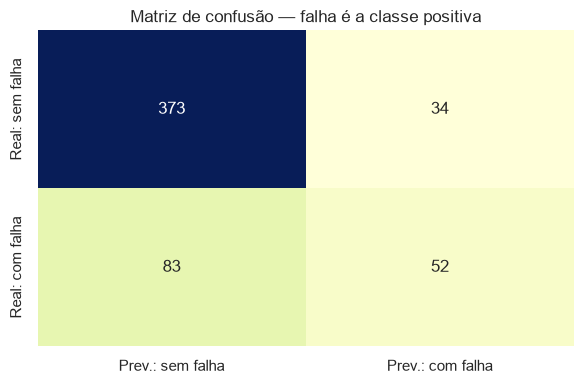

In [4]:
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

metrics = pd.Series({
    "Acurácia — proporção total de acertos": accuracy_score(y_test, y_pred),
    "Precisão — alarmes que correspondiam a falhas": precision_score(
        y_test, y_pred, zero_division=0
    ),
    "Recall — falhas que foram detectadas": recall_score(y_test, y_pred),
})

print(metrics.map(lambda value: f"{value:.1%}").to_string())
print(f"\nTN={tn} | FP={fp} | FN={fn} | TP={tp}")

cm = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Real: sem falha", "Real: com falha"],
    columns=["Prev.: sem falha", "Prev.: com falha"],
)

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", cbar=False, ax=ax)
ax.set_title("Matriz de confusão — falha é a classe positiva")
plt.tight_layout()
plt.show()

## 4. Quais informações o modelo mais utilizou?

A **importância dos atributos** indica quanto cada coluna foi utilizada nas
decisões das árvores do modelo.

Importância não significa causa. Uma coluna pode ajudar a prever uma falha sem
ser a responsável por ela. Ela pode apenas acompanhar outra condição ainda não
medida. Esse indicador indireto também é chamado de **proxy**.

> Pergunta: quais atributos foram construídos em A e quais foram construídos em B?

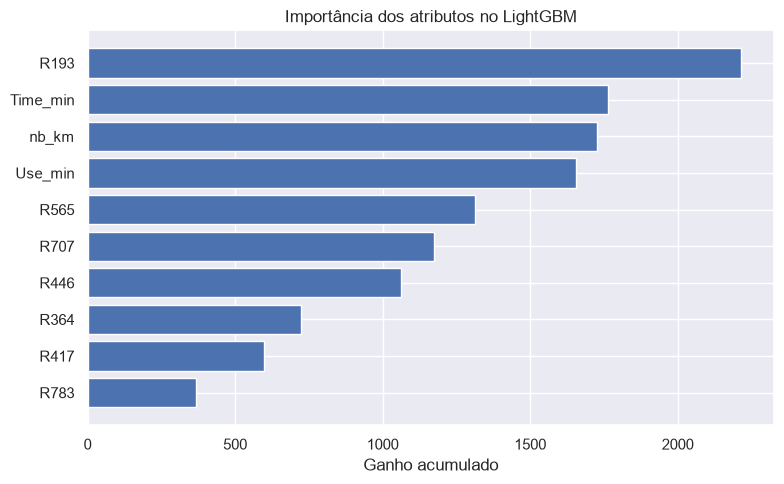

,atributo,importancia
3,R193,2215.505831
0,Time_min,1762.461050
2,nb_km,1727.327001
1,Use_min,1655.225727
7,R565,1311.542872
8,R707,1174.070005
6,R446,1060.593102
4,R364,722.028648
5,R417,597.519206
9,R783,366.965909


In [5]:
importance = (
    pd.DataFrame({
        "atributo": features,
        "importancia": classifier.feature_importances_,
    })
    .sort_values("importancia", ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance["atributo"], importance["importancia"])
ax.set_title("Importância dos atributos no LightGBM")
ax.set_xlabel("Ganho acumulado")
plt.tight_layout()
plt.show()

importance.sort_values("importancia", ascending=False)

## 5. Usando o modelo em novos ativos

`Asset_new_informations.csv` contém ativos cuja situação de falha ainda não é
conhecida. Aplicar um modelo já treinado a novos dados é chamado de **inferência**
ou **scoring**.

Primeiro, ajustaremos os nomes das colunas para que coincidam com os atributos do
treino. Em seguida, calcularemos uma probabilidade de falha para cada ativo.

Essa probabilidade pode ajudar a definir quais ativos merecem análise primeiro,
mas não deve autorizar automaticamente uma ação de manutenção.

In [6]:
new_assets_path = DATA_DIR / "Asset_new_informations.csv"
new_assets = pd.read_csv(new_assets_path)

rename_map = {
    column: column.replace("_Quantity_sum", "")
    for column in new_assets.columns
    if column.endswith("_Quantity_sum")
}
rename_map.update({
    "Time_begin_exploitation": "Time_min",
})

new_assets_model = new_assets.rename(columns=rename_map).copy()
new_assets_model["Use_min"] = 0.0

missing_features = [name for name in features if name not in new_assets_model]
if missing_features:
    raise ValueError(f"Atributos ausentes nos novos ativos: {missing_features}")

new_probability = classifier.predict_proba(
    new_assets_model[features]
)[:, 1]

ranking = (
    pd.DataFrame({
        "Asset": new_assets_model["Asset"],
        "probabilidade_falha": new_probability,
        "classe_limiar_0_50": (new_probability >= 0.50).astype(int),
    })
    .sort_values("probabilidade_falha", ascending=False)
)

print(f"Novos ativos avaliados: {len(ranking)}")
print(f"Acima do limiar 0,50: {ranking['classe_limiar_0_50'].sum()}")
ranking.head(10).style.format({"probabilidade_falha": "{:.1%}"})

Novos ativos avaliados: 80
Acima do limiar 0,50: 0


,Asset,probabilidade_falha,classe_limiar_0_50
11,A605703,43.3%,0
29,A652005,33.8%,0
61,A410604,33.7%,0
23,A657855,25.5%,0
63,A530045,23.2%,0
48,A282186,20.7%,0
1,A039156,20.1%,0
52,A440417,13.3%,0
69,A832878,13.3%,0
9,A089238,12.1%,0


## Fechamento da sequência A → B → C

1. Antes de analisar uma tabela, precisamos saber o que cada linha representa.
2. `Asset` permite relacionar as fontes, mas elas começam em níveis de detalhe
   diferentes.
3. Resumir dados (**agregar**) e juntar tabelas (**join**) envolve escolhas que
   afetam o resultado.
4. Campos vazios e ativos sem resposta conhecida precisam continuar visíveis.
5. Uma probabilidade só pode apoiar uma decisão depois de verificarmos o modelo,
   escolhermos um valor de corte (**limiar**) e discutirmos o custo dos erros.

### Termos que apareceram nesta sequência

- **ETL:** extrair, transformar e carregar dados;
- **granularidade:** o que cada linha representa;
- **chave de integração:** coluna usada para relacionar tabelas;
- **agregação:** resumo de várias linhas;
- **join:** junção de tabelas;
- **atributo ou feature:** informação fornecida ao modelo;
- **alvo ou target:** resposta que queremos prever;
- **inferência:** aplicação do modelo a novos dados.

### Conexão com as próximas aulas

Depois, aprofundaremos qualidade dos dados, gráficos exploratórios, criação de
atributos e avaliação de modelos preditivos.